# 05 · Feature engineering: turning what we learned into columns the models can use

Better columns usually help more than a fancier model. In notebooks 02 and 03 we learned what matters: the hour of the day, the airline, the airport, the weather, the earlier flight of the same plane, and the type of destination. Here we build those as columns.

## The one rule: only what is known 2 hours before departure
The agency wants to warn clients **2 hours before the scheduled departure**. So every column must be known at that moment:

| We may use | We may never use |
|---|---|
| the published schedule, the airline, the route, the distance | the actual departure time and delay (`dep_time`, `dep_delay`) |
| details of the plane | the actual arrival (`arr_time`, `arr_delay`) |
| the weather reading from **2 hours earlier** | the time spent in the air (`air_time`) |
| the same plane's earlier flight, **only if it had already left 2 hours before** | anything built from those |

Using a column that is only known after the flight leaves is called **leakage**: the model would look brilliant on paper and be useless in real life.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz
from src.features import add_congestion, add_lagged_weather, add_previous_flight

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

common.require_processed("flights_clean.parquet", "weather_clean.parquet", "planes_clean.parquet", "destination_groups.parquet", "destination_groups_fit.parquet")
viz.apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 110)

In [2]:
flights = pd.read_parquet(common.PROC / "flights_clean.parquet")
weather = pd.read_parquet(common.PROC / "weather_clean.parquet")
planes = pd.read_parquet(common.PROC / "planes_clean.parquet")
groups = pd.read_parquet(common.PROC / "destination_groups.parquet")
N = len(flights)
assert N == common.FLIGHT_ROWS
print(f"{N:,} flights to build columns for")

435,352 flights to build columns for


## 1. Build the columns
After every step we check that **no flight was lost** (the number of rows stays the same). The three builders in `src/features.py` have unit tests that pin the 2-hour rule on small examples.

**Schedule columns** come straight from the published timetable: hour of the day, day of the week, distance, airline and origin airport.

*We do not use the month.* We have only one year, and the test months (October to December) never appear in the training months (January to September). A model could not learn what "October" means, and would treat it like September, a stormy month. Notebook 04 shows how much the months differ; the models rely on the weather, the hour and the earlier flight instead.

In [3]:
f = flights[["row_id", "part", "late_or_cancelled", "dep_delay", "tailnum", "origin", "dest", "carrier", "distance", "time_hour", "sched_dep_dt"]].copy()
f["hour"] = f["sched_dep_dt"].dt.hour.astype("int8")
f["weekday"] = f["sched_dep_dt"].dt.dayofweek.astype("int8")
assert len(f) == N

**Destination type** from notebook 03 (steady, afternoon build-up, thin routes, or rare). It was built on the training months only (January to September). The same column built from **January to June only** is saved too (`dest_group_fit`): the models are compared and tuned with that one, so the validation months' outcomes cannot leak into the comparison, and the final models use the January-to-September one.

In [4]:
f = f.merge(groups[["dest", "group_id"]], on="dest", how="left").rename(columns={"group_id": "dest_group"})
assert len(f) == N and f["dest_group"].notna().all()
f["dest_group"] = f["dest_group"].astype("int8")
print(f["dest_group"].value_counts().sort_index().to_dict())
groups_fit = pd.read_parquet(common.PROC / "destination_groups_fit.parquet")
f = f.merge(groups_fit[["dest", "group_id"]].rename(columns={"group_id": "dest_group_fit"}), on="dest", how="left")
assert len(f) == N and f["dest_group_fit"].notna().all()
f["dest_group_fit"] = f["dest_group_fit"].astype("int8")

{-1: 445, 0: 195819, 1: 237094, 2: 1994}


**Congestion:** how many flights are scheduled from the same airport in the same hour. The published schedule tells us this in advance.

In [5]:
f = add_congestion(f)
assert len(f) == N
print(f["origin_hour_flights"].describe().round(1).to_dict())

{'count': 435352.0, 'mean': 25.5, 'std': 6.6, 'min': 1.0, '25%': 21.0, '50%': 26.0, '75%': 31.0, 'max': 40.0}


**The plane:** its age in 2023 and its number of seats, joined on the tail number. (The flights with no tail number are handled in section 2b, once the earlier-flight columns exist.)

In [6]:
p = planes[["tailnum", "year", "seats"]].copy()
f = f.merge(p, on="tailnum", how="left")
assert len(f) == N
f["plane_age"] = 2023 - f["year"]
f = f.drop(columns="year")
f = f.sort_values("row_id").reset_index(drop=True)
print(f"{int(f['tailnum'].isna().sum()):,} flights have no tail number | plane details missing for {f['plane_age'].isna().mean():.1%} of flights (no tail number, or a tail number not in the plane table)")

1,913 flights have no tail number | plane details missing for 4.4% of flights (no tail number, or a tail number not in the plane table)


**Weather 2 hours before:** temperature, wind speed, wind gusts, visibility, rain or snow, and air pressure at the departure airport, read **2 hours before the scheduled hour**. `weather_filled` tells us the reading was filled in from an earlier hour in notebook 01.

In [7]:
f = add_lagged_weather(f, weather)
assert len(f) == N
print("flights without a weather reading 2 hours before:", int(f["temp"].isna().sum()))

flights without a weather reading 2 hours before: 838


**The earlier flight of the same plane (the domino effect, notebook 02).** The delay of the plane's closest earlier flight on the same day, **only if that flight had already left at least 2 hours before this one is due**. Otherwise the column is empty and `prev_known = 0`.

In [8]:
f = add_previous_flight(f)
assert len(f) == N and f["row_id"].is_unique
print(f"earlier flight known for {f['prev_known'].mean():.1%} of flights")

earlier flight known for 28.8% of flights


## 2. A leakage check of our own
Beyond the unit tests, we re-check the rule on the real data with a slow, independent method: for 3,000 random flights whose earlier flight is marked "known", we look the earlier flight up directly and confirm it really left at least 2 hours before.

In [9]:
rng = np.random.default_rng(common.SEED)
known_rows = f[f["prev_known"] == 1]
sample = known_rows.iloc[rng.choice(len(known_rows), size=3000, replace=False)]
by_plane = f.dropna(subset=["tailnum"]).sort_values("sched_dep_dt").groupby("tailnum")
violations = 0
for r in sample.itertuples():
    same_day = by_plane.get_group(r.tailnum)
    earlier = same_day[(same_day["sched_dep_dt"] < r.sched_dep_dt) & (same_day["sched_dep_dt"].dt.date == r.sched_dep_dt.date())].iloc[-1]
    left_at = earlier["sched_dep_dt"] + pd.Timedelta(minutes=earlier["dep_delay"])
    violations += int(left_at > r.sched_dep_dt - pd.Timedelta(hours=common.LEAD_HOURS) or earlier["dep_delay"] != r.prev_dep_delay)
print("rule violations among 3,000 checked flights:", violations)
assert violations == 0

rule violations among 3,000 checked flights: 0


## 2b. Flights with no tail number: a trap found by independent reviews
Every flight with **no tail number is a cancelled flight** in this data (all 1,913; 1,831 are United's, and every cancelled United flight is one of them). Left empty, "no plane and no earlier flight" would tell the model that the flight will be cancelled, which it cannot know in real life, where a plane is assigned. So each of these flights gets the **plane (seats, age) and the earlier-flight columns (`prev_known`, `prev_dep_delay`) of a randomly drawn real flight of the same airline to the same destination** (fixed seed; January-September flights only; if fewer than 10 such flights exist, the same airline and the same 500-mile distance band, then the same airline).

Three earlier attempts failed, and a test caught each: the same median plane for everybody was a fingerprint; a plane drawn from any airline still stood out among United's own planes (AUC 0.90 inside United); and a plane of the right airline but the wrong route still stood out (0.56 from the distance alone, 0.74 once the plane columns were added), while `prev_known` was 0 for every cancelled United flight. Judged inside United and Frontier, where almost all of these flights are, the plane and earlier-flight columns now add almost nothing to the distance (tests in `tests/test_outputs.py`). An airline with no plane records at all (Allegiant, 3 flights) keeps empty columns, which is what its other flights look like too.

In [10]:
no_tail = f["tailnum"].isna()
assert f.loc[no_tail, "dep_delay"].isna().all(), "the flights with no tail number are no longer all cancelled flights"
COPIED, MIN_DONORS = ["seats", "plane_age", "prev_known", "prev_dep_delay"], 10
f[COPIED] = f[COPIED].astype("float64")
f["distance_band"] = (f["distance"] // 500).astype(int).astype(str)
f["same_route"] = f["carrier"] + "|" + f["dest"]
f["same_band"] = f["carrier"] + "|" + f["distance_band"]
donors = f.loc[(f["part"] != "test") & f["tailnum"].notna() & f["seats"].notna() & f["plane_age"].notna()]      # January-September flights only
rng = np.random.default_rng(common.SEED)
pending, filled = f.index[no_tail], {}
for level in ["same_route", "same_band", "carrier"]:
    pools = {key: g.index.to_numpy() for key, g in donors.groupby(level) if len(g) >= MIN_DONORS}
    unfilled = []
    for key, rows in f.loc[pending].groupby(level):
        if key in pools:
            f.loc[rows.index, COPIED] = donors.loc[rng.choice(pools[key], size=len(rows)), COPIED].to_numpy()
            filled[level] = filled.get(level, 0) + len(rows)
        else:
            unfilled.extend(rows.index)
    pending = pd.Index(unfilled)
f["prev_known"] = f["prev_known"].astype("int8")
f = f.drop(columns=["distance_band", "same_route", "same_band"])
assert len(f) == N
print(f"{int(no_tail.sum()):,} flights with no tail number (all cancelled): donors from the same airline and destination for {filled.get('same_route', 0):,}, same airline and distance band for {filled.get('same_band', 0):,}, same airline for {filled.get('carrier', 0):,}; {len(pending)} left empty (an airline with no plane records)")

1,913 flights with no tail number (all cancelled): donors from the same airline and destination for 1,910, same airline and distance band for 0, same airline for 0; 3 left empty (an airline with no plane records)


## 3. The table of new columns
One line per column: what it is, why it could help, and **known in advance: yes**, with the reason we know it.

In [11]:
TABLE = [
    ("hour", "Scheduled departure hour (0-23)", "The risk of delay climbs through the day (finding 1).", "published schedule"),
    ("weekday", "Day of the week (0 = Monday)", "Some days are busier or more disrupted than others.", "published schedule"),
    ("distance", "Distance of the flight in miles", "Longer routes may behave differently (and a proxy for the route).", "published schedule"),
    ("carrier", "Airline code", "Airlines differ a lot in reliability (finding 3).", "published schedule"),
    ("origin", "Departure airport: JFK, LGA or EWR", "The three airports have different delay levels.", "published schedule"),
    ("dest_group", "Type of destination from notebook 03 (0 steady, 1 afternoon build-up, 2 thin routes, -1 rare)", "Packs the delay pattern of 118 destinations into 4 values.", "built from January-September only"),
    ("origin_hour_flights", "Flights scheduled from the same airport in the same hour", "A crowded hour means queues and knock-on delays.", "published schedule"),
    ("plane_age", "Age of the plane in 2023 (years)", "Older planes may need more turnaround time.", "plane table, known when the flight is scheduled"),
    ("seats", "Number of seats on the plane", "Plane size separates small regional planes from big ones.", "plane table"),
    ("temp", "Temperature (F) 2 hours before the scheduled hour", "Weather affects how many flights an airport can handle (finding 4).", "weather reading from 2 hours before"),
    ("wind_speed", "Wind speed (mph) 2 hours before", "Strong wind slows departures.", "weather reading from 2 hours before"),
    ("wind_gust", "Wind gusts (mph) 2 hours before", "Gusts can stop departures.", "weather reading from 2 hours before"),
    ("visib", "Visibility (miles) 2 hours before", "Low visibility cuts airport capacity.", "weather reading from 2 hours before"),
    ("precip", "Rain or snow (inches) 2 hours before", "Rain and snow cause delays (finding 4).", "weather reading from 2 hours before"),
    ("pressure", "Air pressure (millibars) 2 hours before", "Falling pressure often comes with a storm.", "weather reading from 2 hours before"),
    ("weather_filled", "1 if that weather reading was filled in from an earlier hour", "Tells the model how fresh the reading is.", "weather table"),
    ("prev_dep_delay", "Delay (minutes) of the same plane's earlier flight today, if it left 2+ hours before", "The domino effect: the strongest signal we found (finding 2).", "earlier flight had already left 2 hours before"),
    ("prev_known", "1 if the earlier flight's delay is known at prediction time", "Tells the model when the previous delay column is empty.", "earlier flight had already left 2 hours before"),
]
table = pd.DataFrame(TABLE, columns=["feature", "what", "why", "known_because"])
table["known_in_advance"] = "yes"
FORBIDDEN = {"dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"}
assert not (set(table["feature"]) & FORBIDDEN) and set(table["feature"]) <= set(f.columns)
table[["feature", "what", "why", "known_in_advance", "known_because"]].to_csv(common.REPORTS / "05_feature_table.csv", index=False)
print(f"{len(table)} new columns, all known in advance")
print(table[["feature", "known_because"]].to_string(index=False))

18 new columns, all known in advance
            feature                                   known_because
               hour                              published schedule
            weekday                              published schedule
           distance                              published schedule
            carrier                              published schedule
             origin                              published schedule
         dest_group               built from January-September only
origin_hour_flights                              published schedule
          plane_age plane table, known when the flight is scheduled
              seats                                     plane table
               temp             weather reading from 2 hours before
         wind_speed             weather reading from 2 hours before
          wind_gust             weather reading from 2 hours before
              visib             weather reading from 2 hours before
           

## 4. How much is each column missing?
Missing values are not a mistake: they mean "not known at prediction time" (for example, no earlier flight of that plane yet). The models handle them explicitly.

In [12]:
missing = f[table["feature"].tolist()].isna().mean().sort_values(ascending=False)
print((missing[missing > 0] * 100).round(1).to_string())

prev_dep_delay    71.1
plane_age          3.9
wind_speed         3.5
wind_gust          3.5
seats              2.2
visib              0.3
pressure           0.2
temp               0.2
precip             0.2


## 5. Are the new columns linked to what we predict?
We measure how strongly each numeric column moves with (a) the first target, *late or cancelled*, and (b) the second candidate target, *minutes of delay* (for flights that left), using a **rank correlation** (0 = unrelated, 1 = always together; the sign says the direction). Only the training months are used.

In [13]:
train = f[f["part"] != "test"]
numeric = [c for c in table["feature"] if c not in ("carrier", "origin")]
corr_late = {c: train[c].corr(train["late_or_cancelled"], method="spearman") for c in numeric}
left = train[train["dep_delay"].notna()]
corr_min = {c: left[c].corr(left["dep_delay"], method="spearman") for c in numeric}
corr = pd.DataFrame({"with_late_or_cancelled": corr_late, "with_minutes_of_delay": corr_min}).round(3)
corr = corr.reindex(corr["with_late_or_cancelled"].abs().sort_values(ascending=False).index)
print(corr.to_string())
print("\nlate-or-cancelled rate by airline (min and max):", train.groupby("carrier")["late_or_cancelled"].mean().round(3).agg(["min", "max"]).to_dict())
print("by origin:", train.groupby("origin")["late_or_cancelled"].mean().round(3).to_dict())

                     with_late_or_cancelled  with_minutes_of_delay
prev_dep_delay                        0.269                  0.310
hour                                  0.225                  0.217
temp                                  0.125                  0.106
pressure                             -0.101                 -0.077
visib                                -0.099                 -0.098
precip                                0.093                  0.079
seats                                 0.085                  0.192
dest_group                            0.076                  0.193
origin_hour_flights                  -0.073                 -0.100
prev_known                            0.066                  0.041
distance                              0.050                  0.147
wind_gust                             0.040                  0.030
wind_speed                            0.040                  0.030
weekday                               0.036                  0

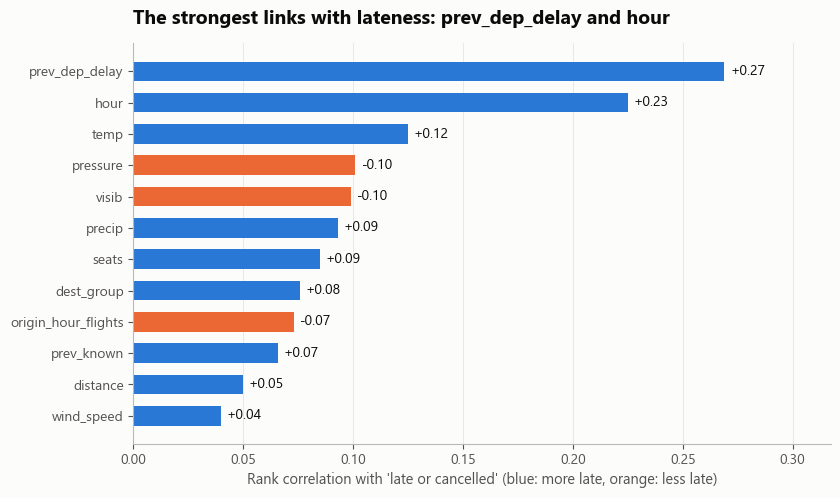

In [14]:
top = corr["with_late_or_cancelled"].dropna().sort_values(key=lambda s: s.abs()).tail(12)
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top.index, top.abs(), color=[viz.BLUE if v > 0 else viz.ORANGE for v in top], height=0.62)
for name, v in zip(top.index, top):
    ax.annotate(f"{v:+.2f}", (abs(v), name), xytext=(4, 0), textcoords="offset points", va="center", fontsize=10)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(0, top.abs().max() * 1.18)
best = top.abs().sort_values(ascending=False).index[:2]
ax.set_title(f"The strongest links with lateness: {best[0]} and {best[1]}")
ax.set_xlabel("Rank correlation with 'late or cancelled' (blue: more late, orange: less late)")
chart = viz.save_figure(fig, "05_feature_links.png")
plt.show()

**Reading it.**
- The earlier flight's delay and the hour of the day move most with lateness, as found in notebook 02. (The earlier-flight link is measured only on the 29% of flights where it is known.)
- Single weather columns are weaker on their own: bad weather is rare (about 1 flight in 6) and each reading shows one aspect. The models can combine them.
- **A caution on temperature:** its positive link does not mean heat delays flights. The summer months were the worst (notebook 04), and summer is warm, so temperature partly stands in for the season. We keep it, but we will not tell the business that heat causes delays.
- Airline and origin airport are categories, so a correlation does not apply: the spread in their late rates is printed above (airlines range from 10% to 49%).

## 6. Save the columns for the models
One row per flight, in the original order: `row_id`, `part` (fit/valid/test), the two targets (`late_or_cancelled`, `dep_delay`) and the 18 new columns. The targets are stored only so the models can learn from them. They are never inputs.

In [15]:
features = f[["row_id", "part", "late_or_cancelled", "dep_delay"] + table["feature"].tolist() + ["dest_group_fit"]]
assert len(features) == N and features["row_id"].is_unique
features.to_parquet(common.PROC / "features.parquet", index=False)
print("saved", features.shape, "| flights per part:", features["part"].value_counts().to_dict())

saved (435352, 23) | flights per part: {'fit': 222402, 'valid': 108481, 'test': 104469}
